In [1]:
try:
    import google.colab.drive as _d
    _d.mount = lambda *a, **k: print('Drive ya está montado (notebook 06)')
except Exception as e:
    print('sin google.colab:', e)

# 03 — Entrenamiento y comparación de modelos (Ibague)

Entrena los tres modelos sobre la misma tabla, con la misma partición y las mismas métricas, y los compara contra la persistencia.

| Sección | Modelo | Responsable |
|---|---|---|
| 4 | Regresión logística regularizada | Integrante A |
| 5 | XGBoost | Integrante B |
| 6 | Binomial negativa (conteos → probabilidad de exceso) | Integrante C |

Cada integrante ajusta **solo su sección** (hiperparámetros, variables). Las secciones 1–3 y 7–8 son comunes y no se tocan, para que la comparación sea justa.

**Flujo de cada modelo**
1. Elegir hiperparámetros y umbral de decisión con **train → val**.
2. Reentrenar con **train + val** usando lo elegido.
3. Evaluar **una sola vez** en **test** (2023–2025). Si se vuelve a ajustar mirando test, el resultado deja de ser válido.

## 1. Datos

In [2]:
!pip install -q xgboost statsmodels

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score
import xgboost as xgb
import statsmodels.api as sm

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

RUTA = '/content/drive/MyDrive/Datos/dengue/procesado'
COD_MUN = '50001'

tabla = pd.read_csv(f'{RUTA}/tabla_modelado_{COD_MUN}.csv', parse_dates=['mes_objetivo'])
nivel2 = pd.read_csv(f'{RUTA}/serie_nivel2_{COD_MUN}.csv', parse_dates=['mes']).set_index('mes')

# casos y umbral del mes objetivo: solo los usa la binomial negativa (como objetivo, no como predictor)
tabla['casos_obj'] = tabla['mes_objetivo'].map(nivel2['casos'])
tabla['umbral_obj'] = tabla['mes_objetivo'].map(nivel2['umbral'])

NO_PREDICTORES = ('municipio', 'mes_objetivo', 'pandemia', 'exceso', 'split', 'casos_obj', 'umbral_obj')
PREDICTORES = [c for c in tabla.columns if c not in NO_PREDICTORES]
ULTIMO = [c for c in PREDICTORES if c.startswith('exceso_t-')][0]

train, val, test = (tabla[tabla.split == s].copy() for s in ('train', 'val', 'test'))
trval = pd.concat([train, val])
print(f'{len(PREDICTORES)} predictores | train {len(train)} ({train.exceso.sum()} excesos) | '
      f'val {len(val)} ({val.exceso.sum()}) | test {len(test)} ({test.exceso.sum()})')

Drive ya está montado (notebook 06)
16 predictores | train 82 (22 excesos) | val 48 (12) | test 36 (25)


## 2. Métricas comunes
- **recall**: de los meses en exceso, cuántos se anticipan (lo más importante para una alerta).
- **precision**: de las alertas, cuántas eran reales.
- **F1**: balance entre las dos.
- **PR-AUC**: calidad de la probabilidad, sin depender del umbral de decisión.
- **recall_inicios**: de los **inicios de brote** (normal → exceso), cuántos se anticipan. La persistencia siempre saca 0.

El **umbral de decisión** (a partir de qué probabilidad se emite alerta) se elige en validación maximizando F1, y luego se deja fijo para test.

In [4]:
def evaluar(g, pred, prob=None):
    y, pred = g['exceso'], pd.Series(np.asarray(pred).astype(int), index=g.index)
    inicio = (y == 1) & (g[ULTIMO] == 0)
    return {'recall': recall_score(y, pred, zero_division=0),
            'precision': precision_score(y, pred, zero_division=0),
            'f1': f1_score(y, pred, zero_division=0),
            'pr_auc': average_precision_score(y, prob) if prob is not None else np.nan,
            'recall_inicios': pred[inicio].mean() if inicio.any() else np.nan,
            'n_inicios': int(inicio.sum())}

def elegir_umbral(y, prob):
    grilla = np.arange(0.05, 0.96, 0.05)
    f1s = [f1_score(y, prob >= u, zero_division=0) for u in grilla]
    return float(grilla[int(np.argmax(f1s))])

RESULTADOS, PROBS_TEST = {}, {}

## 3. Línea base: persistencia

In [5]:
RESULTADOS['Persistencia'] = {s: evaluar(g, g[ULTIMO]) for s, g in [('val', val), ('test', test)]}
pd.DataFrame(RESULTADOS['Persistencia']).T.round(2)

,recall,precision,f1,pr_auc,recall_inicios,n_inicios
val,0.67,0.67,0.67,NaN,0.0,4.0
test,0.80,0.83,0.82,NaN,0.0,5.0


## 4. Regresión logística regularizad
Variables estandarizadas, penalización L2 y `class_weight='balanced'`. Se elige la fuerza de regularización `C` en validación. Los coeficientes permiten interpretar qué variables empujan hacia el exceso.

Cada modelo está escrito como una función que recibe la lista de variables (`cols`): así la sección 9 puede repetirlo sin clima con exactamente el mismo procedimiento.

{'C': 0.3, 'umbral': 0.7500000000000001}


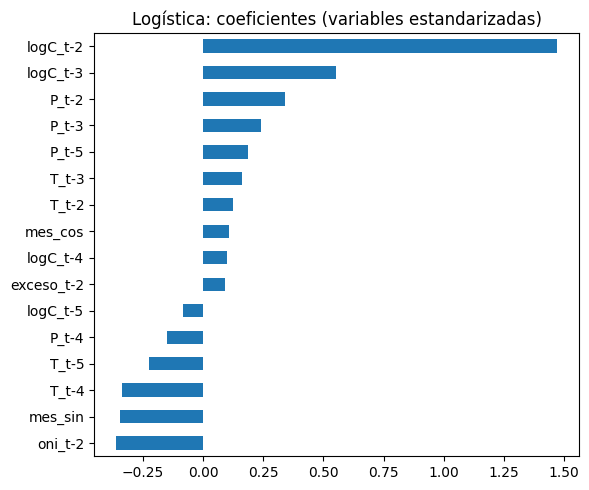

In [6]:
GRILLA_C = [0.01, 0.03, 0.1, 0.3, 1, 3]

def logistica(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight='balanced', max_iter=5000))

def ajustar_logistica(cols):
    pr = {C: average_precision_score(val.exceso, logistica(C).fit(train[cols], train.exceso)
                                     .predict_proba(val[cols])[:, 1]) for C in GRILLA_C}
    C = max(pr, key=pr.get)
    p_val = logistica(C).fit(train[cols], train.exceso).predict_proba(val[cols])[:, 1]
    u = elegir_umbral(val.exceso, p_val)
    modelo = logistica(C).fit(trval[cols], trval.exceso)
    p_test = modelo.predict_proba(test[cols])[:, 1]
    res = {'val': evaluar(val, p_val >= u, p_val), 'test': evaluar(test, p_test >= u, p_test)}
    return res, p_test, modelo, {'C': C, 'umbral': u}

RESULTADOS['Logística'], PROBS_TEST['Logística'], modelo_log, info = ajustar_logistica(PREDICTORES)
print(info)
coef = pd.Series(modelo_log[-1].coef_[0], index=PREDICTORES).sort_values()
coef.plot.barh(figsize=(6, 5), title='Logística: coeficientes (variables estandarizadas)'); plt.tight_layout(); plt.show()

## 5. XGBoost
Con 80 meses de entrenamiento el riesgo principal es **sobreajuste**: árboles poco profundos, pocos árboles, tasa de aprendizaje baja y submuestreo. La grilla es pequeña a propósito.

{'max_depth': 2, 'n_estimators': 50, 'umbral': 0.45}


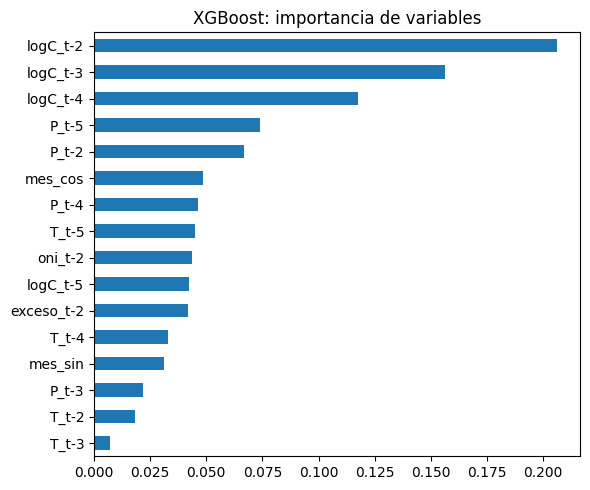

In [7]:
GRILLA_XGB = [dict(max_depth=d, n_estimators=n, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                   min_child_weight=3, reg_lambda=5)
              for d in (1, 2, 3) for n in (50, 100, 200)]

def xgboost_(params, g):
    peso = (g.exceso == 0).sum() / max(g.exceso.sum(), 1)
    return xgb.XGBClassifier(**params, scale_pos_weight=peso, eval_metric='logloss', random_state=42)

def ajustar_xgb(cols):
    pr = [average_precision_score(val.exceso, xgboost_(p, train).fit(train[cols], train.exceso)
                                  .predict_proba(val[cols])[:, 1]) for p in GRILLA_XGB]
    P = GRILLA_XGB[int(np.argmax(pr))]
    p_val = xgboost_(P, train).fit(train[cols], train.exceso).predict_proba(val[cols])[:, 1]
    u = elegir_umbral(val.exceso, p_val)
    modelo = xgboost_(P, trval).fit(trval[cols], trval.exceso)
    p_test = modelo.predict_proba(test[cols])[:, 1]
    res = {'val': evaluar(val, p_val >= u, p_val), 'test': evaluar(test, p_test >= u, p_test)}
    return res, p_test, modelo, {'max_depth': P['max_depth'], 'n_estimators': P['n_estimators'], 'umbral': u}

RESULTADOS['XGBoost'], PROBS_TEST['XGBoost'], modelo_xgb, info = ajustar_xgb(PREDICTORES)
print(info)
imp = pd.Series(modelo_xgb.feature_importances_, index=PREDICTORES).sort_values()
imp.plot.barh(figsize=(6, 5), title='XGBoost: importancia de variables'); plt.tight_layout(); plt.show()

## 6. Binomial negativa — Integrante C
Enfoque distinto: en vez de clasificar, **predice el número de casos** del mes objetivo y calcula la probabilidad de que supere el umbral del canal:

P(exceso) = P(casos > umbral) con casos ~ Binomial Negativa(μ, α)

Es el modelo estándar para conteos con sobredispersión (la varianza de los casos es mucho mayor que la media). Ventaja: además de la alerta, da un número esperado de casos.



/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:3709: RuntimeWarning: invalid value encountered in log
  llf = coeff + size * np.log(prob) + endog * np.log(1 - prob)
/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:3709: RuntimeWarning: invalid value encountered in log
  llf = coeff + size * np.log(prob) + endog * np.log(1 - prob)


{'umbral': 0.3, 'alpha_dispersion': np.float64(0.11)}


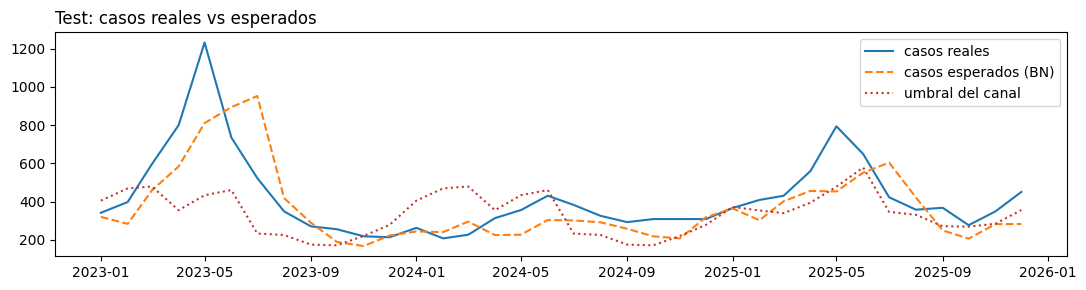

In [8]:
PENAL_NB = 0.5   # regularización L1 de los coeficientes (no se penaliza la constante ni la dispersión)

def X_(g, cols, esc):
    return sm.add_constant(pd.DataFrame(esc.transform(g[cols]), columns=cols, index=g.index), has_constant='add')

def ajustar_bn(g, cols):
    esc = StandardScaler().fit(g[cols])
    penal = np.r_[0, np.full(len(cols), PENAL_NB), 0]
    res = sm.NegativeBinomial(g['casos_obj'], X_(g, cols, esc)).fit_regularized(alpha=penal, disp=0, maxiter=2000)
    return res, esc

def prob_exceso(res, esc, g, cols):
    mu = res.predict(X_(g, cols, esc))
    n = 1 / res.params['alpha']
    return np.asarray(1 - stats.nbinom.cdf(np.floor(g['umbral_obj']), n, n / (n + mu))), mu

def ajustar_binomial(cols):
    p_val, _ = prob_exceso(*ajustar_bn(train, cols), val, cols)
    u = elegir_umbral(val.exceso, p_val)
    modelo, esc = ajustar_bn(trval, cols)
    p_test, mu_test = prob_exceso(modelo, esc, test, cols)
    res = {'val': evaluar(val, p_val >= u, p_val), 'test': evaluar(test, p_test >= u, p_test)}
    return res, p_test, (modelo, mu_test), {'umbral': u, 'alpha_dispersion': round(modelo.params['alpha'], 2)}

RESULTADOS['Binomial negativa'], PROBS_TEST['Binomial negativa'], (modelo_bn, mu_test), info = ajustar_binomial(PREDICTORES)
print(info)

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(test['mes_objetivo'], test['casos_obj'], label='casos reales')
ax.plot(test['mes_objetivo'], mu_test, label='casos esperados (BN)', ls='--')
ax.plot(test['mes_objetivo'], test['umbral_obj'], label='umbral del canal', color='#c0392b', ls=':')
ax.set_title('Test: casos reales vs esperados', loc='left'); ax.legend(); plt.tight_layout(); plt.show()

In [9]:
# ===== 6b. Red neuronal pequeña (MLP) — experimento =====
from sklearn.neural_network import MLPClassifier

GRILLA_MLP = [dict(hidden_layer_sizes=h, alpha=a) for h in [(4,), (8,), (8, 4)] for a in [0.1, 1.0, 10.0]]
SEMILLAS = range(10)   # con pocos datos la red cambia según la semilla: se promedian 10

def red(params, semilla):
    return make_pipeline(StandardScaler(), MLPClassifier(**params, activation='relu', solver='lbfgs',
                                                         max_iter=5000, random_state=semilla))

def prob_promedio(params, g_fit, g_pred, cols):
    return np.mean([red(params, s).fit(g_fit[cols], g_fit.exceso).predict_proba(g_pred[cols])[:, 1]
                    for s in SEMILLAS], axis=0)

def ajustar_mlp(cols):
    pr = [average_precision_score(val.exceso, prob_promedio(p, train, val, cols)) for p in GRILLA_MLP]
    P = GRILLA_MLP[int(np.argmax(pr))]
    p_val = prob_promedio(P, train, val, cols)
    u = elegir_umbral(val.exceso, p_val)
    p_test = prob_promedio(P, trval, test, cols)
    res = {'val': evaluar(val, p_val >= u, p_val), 'test': evaluar(test, p_test >= u, p_test)}
    pr_ind = [average_precision_score(test.exceso, red(P, s).fit(trval[cols], trval.exceso)
                                      .predict_proba(test[cols])[:, 1]) for s in SEMILLAS]
    return res, p_test, None, {**P, 'umbral': u, 'pr_auc_test_por_semilla': (round(min(pr_ind), 2), round(max(pr_ind), 2))}

RESULTADOS['Red neuronal (MLP)'], PROBS_TEST['Red neuronal (MLP)'], _, info = ajustar_mlp(PREDICTORES)
print(info)

{'hidden_layer_sizes': (4,), 'alpha': 10.0, 'umbral': 0.5, 'pr_auc_test_por_semilla': (np.float64(0.96), np.float64(0.96))}


## 7. Comparación final
Validación sirve para elegir; **test es el resultado que va al informe**. Un modelo solo aporta si le gana a la persistencia, sobre todo en `recall_inicios`.

Con 2 inicios de brote en test, `recall_inicios` solo puede valer 0, 0,5 o 1: hay que reportarlo con esa advertencia.

In [10]:
comparacion = pd.concat({m: pd.DataFrame(r).T for m, r in RESULTADOS.items()}).round(2)
comparacion.index.names = ['modelo', 'conjunto']
comparacion.xs('test', level='conjunto')

,recall,precision,f1,pr_auc,recall_inicios,n_inicios
modelo,,,,,,
Persistencia,0.80,0.83,0.82,NaN,0.0,5.0
Logística,0.48,1.00,0.65,0.97,0.0,5.0
XGBoost,0.96,0.89,0.92,0.99,1.0,5.0
Binomial negativa,0.88,0.96,0.92,0.98,1.0,5.0
Red neuronal (MLP),0.60,1.00,0.75,0.96,0.0,5.0


In [11]:
comparacion.xs('val', level='conjunto')

,recall,precision,f1,pr_auc,recall_inicios,n_inicios
modelo,,,,,,
Persistencia,0.67,0.67,0.67,NaN,0.0,4.0
Logística,0.67,0.80,0.73,0.83,0.0,4.0
XGBoost,0.83,0.77,0.80,0.86,0.5,4.0
Binomial negativa,1.00,0.80,0.89,0.96,1.0,4.0
Red neuronal (MLP),0.67,0.89,0.76,0.82,0.0,4.0


## 8. Probabilidad de exceso en test

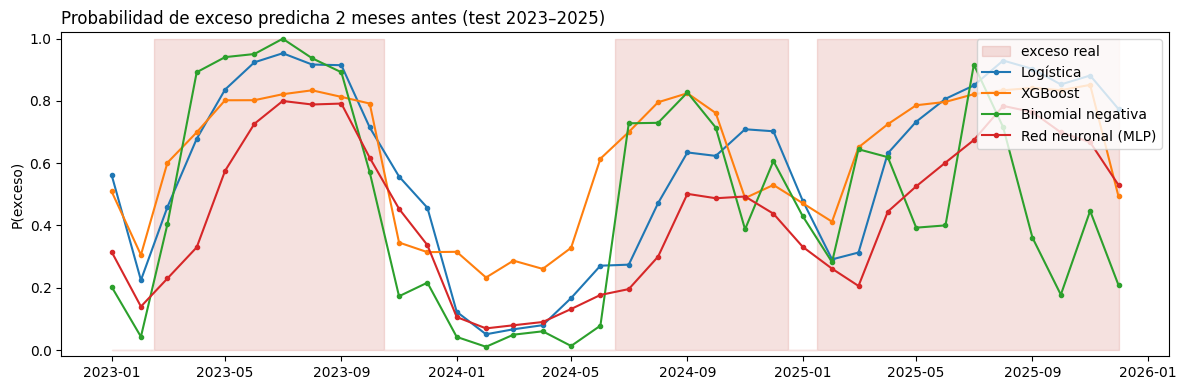

In [12]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(test['mes_objetivo'], 0, test['exceso'], step='mid', alpha=0.15, color='#c0392b', label='exceso real')
for m, p in PROBS_TEST.items():
    ax.plot(test['mes_objetivo'], p, marker='o', ms=3, label=m)
ax.set_ylim(-0.02, 1.02); ax.set_ylabel('P(exceso)')
ax.set_title('Probabilidad de exceso predicha 2 meses antes (test 2023–2025)', loc='left')
ax.legend(loc='upper right'); plt.tight_layout(); plt.show()

comparacion.to_csv(f'{RUTA}/comparacion_modelos_{COD_MUN}.csv')

## 9. ¿El clima aporta?
Cada modelo se reentrena con el **mismo procedimiento** (misma grilla, mismo criterio de umbral, misma partición) pero con menos variables:

| Conjunto | Variables |
|---|---|
| **Completo** | las 16 |
| **Sin clima local** | sin lluvia ni temperatura (queda el ONI) |
| **Sin clima** | sin lluvia, temperatura ni ONI: solo casos, estacionalidad y estado actual |

Si "Sin clima" rinde igual que "Completo", el modelo está prediciendo con la inercia de la epidemia y el clima no aporta. Si "Sin clima local" rinde igual que "Completo", lo que aporta es El Niño y no el clima del municipio.

**Ojo con la lectura:** test tiene 36 meses y una sola epidemia. Diferencias de pocas centésimas no son concluyentes; lo que vale es si el patrón se repite en validación y en test, y en los tres modelos.

In [13]:
CONJUNTOS = {
    'Completo':        PREDICTORES,
    'Sin clima local': [c for c in PREDICTORES if not c.startswith(('P_', 'T_'))],
    'Sin clima':       [c for c in PREDICTORES if not c.startswith(('P_', 'T_', 'oni'))],
}
AJUSTES = {'Logística': ajustar_logistica, 'XGBoost': ajustar_xgb, 'Binomial negativa': ajustar_binomial,
           'Red neuronal (MLP)': ajustar_mlp}
filas = []
for modelo, ajustar in AJUSTES.items():
    for conjunto, cols in CONJUNTOS.items():
        res = RESULTADOS[modelo] if conjunto == 'Completo' else ajustar(cols)[0]
        for parte in ('val', 'test'):
            filas.append({'modelo': modelo, 'variables': conjunto, 'n_vars': len(cols), 'conjunto': parte,
                          **{k: res[parte][k] for k in ('f1', 'pr_auc', 'recall', 'precision', 'recall_inicios')}})
clima = pd.DataFrame(filas).set_index(['modelo', 'variables', 'conjunto']).round(2)
clima.to_csv(f'{RUTA}/comparacion_clima_{COD_MUN}.csv')
clima.xs('test', level='conjunto')

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:3709: RuntimeWarning: invalid value encountered in log
  llf = coeff + size * np.log(prob) + endog * np.log(1 - prob)
/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:3709: RuntimeWarning: invalid value encountered in log
  llf = coeff + size * np.log(prob) + endog * np.log(1 - prob)


n_vars    f1  pr_auc  recall  precision  \
modelo             variables                                                  
Logística          Completo             16  0.65    0.97    0.48       1.00   
                   Sin clima local       8  0.94    0.99    1.00       0.89   
                   Sin clima             7  0.72    0.98    0.56       1.00   
XGBoost            Completo             16  0.92    0.99    0.96       0.89   
                   Sin clima local       8  0.89    0.98    1.00       0.81   
                   Sin clima             7  0.89    0.98    0.96       0.83   
Binomial negativa  Completo             16  0.92    0.98    0.88       0.96   
                   Sin clima local       8  0.92    0.99    0.92       0.92   
                   Sin clima             7  0.81    0.98    0.68       1.00   
Red neuronal (MLP) Completo             16  0.75    0.96    0.60       1.00   
                   Sin clima local       8  0.88    0.97    0.84       0.91   
                   Sin clima             7  0.89    0.97    0.84       0.95   

                                    recall_inicios  
modelo             variables                        
Logística          Completo                    0.0  
                   Sin clima local             1.0  
                   Sin clima                   0.4  
XGBoost            Completo                    1.0  
                   Sin clima local             1.0  
                   Sin clima                   1.0  
Binomial negativa  Completo                    1.0  
                   Sin clima local             1.0  
                   Sin clima                   0.8  
Red neuronal (MLP) Completo                    0.0  
                   Sin clima local             0.2  
                   Sin clima                   1.0

In [14]:
clima.xs('val', level='conjunto')

n_vars    f1  pr_auc  recall  precision  \
modelo             variables                                                  
Logística          Completo             16  0.73    0.83    0.67       0.80   
                   Sin clima local       8  0.74    0.87    0.83       0.67   
                   Sin clima             7  0.87    0.92    0.83       0.91   
XGBoost            Completo             16  0.80    0.86    0.83       0.77   
                   Sin clima local       8  0.79    0.89    0.92       0.69   
                   Sin clima             7  0.77    0.89    0.83       0.71   
Binomial negativa  Completo             16  0.89    0.96    1.00       0.80   
                   Sin clima local       8  0.89    0.97    1.00       0.80   
                   Sin clima             7  0.87    0.96    0.83       0.91   
Red neuronal (MLP) Completo             16  0.76    0.82    0.67       0.89   
                   Sin clima local       8  0.76    0.87    0.67       0.89   
                   Sin clima             7  0.87    0.93    0.83       0.91   

                                    recall_inicios  
modelo             variables                        
Logística          Completo                   0.00  
                   Sin clima local            0.50  
                   Sin clima                  0.50  
XGBoost            Completo                   0.50  
                   Sin clima local            0.75  
                   Sin clima                  0.50  
Binomial negativa  Completo                   1.00  
                   Sin clima local            1.00  
                   Sin clima                  0.50  
Red neuronal (MLP) Completo                   0.00  
                   Sin clima local            0.00  
                   Sin clima                  0.50

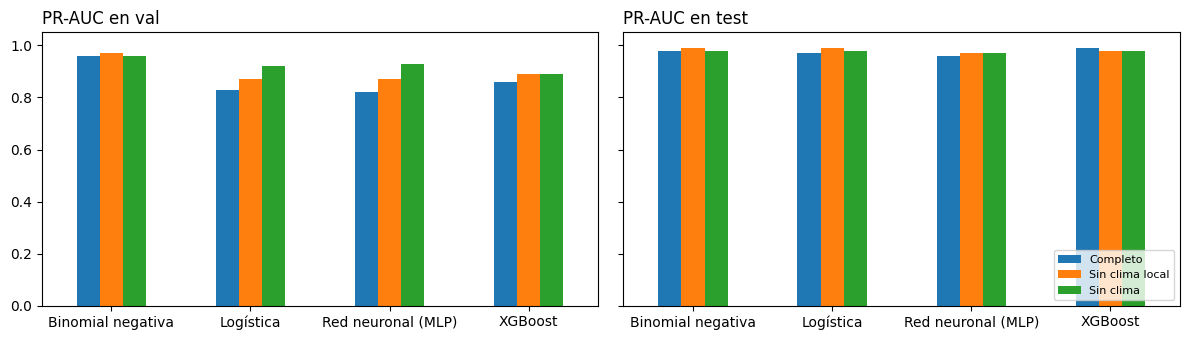

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, parte in zip(axes, ('val', 'test')):
    clima.xs(parte, level='conjunto')['pr_auc'].unstack('variables')[list(CONJUNTOS)].plot.bar(ax=ax, rot=0)
    ax.set_title(f'PR-AUC en {parte}', loc='left'); ax.set_xlabel(''); ax.set_ylim(0, 1.05)
axes[1].legend(loc='lower right', fontsize=8); axes[0].get_legend().remove()
plt.tight_layout(); plt.show()

In [16]:
import os, joblib
SAL = f'{RUTA}/modelos_{COD_MUN}'
os.makedirs(SAL, exist_ok=True)

# modelos entrenados (train + val)
joblib.dump(modelo_log, f'{SAL}/logistica.pkl')
modelo_xgb.save_model(f'{SAL}/xgboost.json')
modelo_bn.save(f'{SAL}/binomial_negativa.pkl')

# predicciones de test (para tablas o gráficos del informe)
pred = test[['mes_objetivo', 'exceso', 'casos_obj', 'umbral_obj']].copy()
for m, p in PROBS_TEST.items():
    pred[f'prob_{m}'] = p
pred.to_csv(f'{SAL}/predicciones_test.csv', index=False)

# todos los gráficos abiertos, en PNG para el informe
for i, num in enumerate(plt.get_fignums()):
    plt.figure(num).savefig(f'{SAL}/figura_{i+1}.png', dpi=200, bbox_inches='tight')
print('Guardado en', SAL)

Guardado en /content/drive/MyDrive/Datos/dengue/procesado/modelos_50001
